# Crank-Nicolson Black-Scholes solver

In this notebook I will be testing my Crank-Nicolson solver, as well as giving some exposition about the maths behind it.

I will make the assumption that the underlying stock price evolves under Geometric Brownian Motion (GBM). On the resulting Black-Scholes equation I will perform the transformation $\tau = T - t$, and the following terminal/boundary conditions:

Terminal condition: $V(S,T) = max(S-K,0)$

Boundary conditions: $V(0,t) = 0, V(S_{max},t) = S_{max} - Ke^{-r(T-t)}$

I will also take $S_{max} = 4K$, as this is large enough that the upper bound solution approaches the theoretically asymptotic value.

## Transforming the Black-Scholes equation using $\tau = T - t$

The Black-Scholes equation as it evolves from GBM: 

$$  \frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS \frac{\partial V}{\partial S} - rV = 0. $$

Using the time to maturity variable $\tau$ this becomes (derivation in report):

$$\frac{\partial U}{\partial \tau}=\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 U}{\partial S^2}+ rS \frac{\partial U}{\partial S}- rU$$

The terminal condition becomes an initial condition: $U(S,0) = \max(S-K,0)$.

The boundary conditions remain the same: $U(0,t) = 0, U(S \to \infty,t) = S - Ke^{-r\tau}$

## Spacial discretisation

The spacial domain $[0,S_{max}]$ is discretised into M uniformly spaced grid points with step size $\Delta S = \frac{S_{max}}{M}.$ The value of the numerical solution at the i-th spacial point and j-th temporal point is denoted $U_i^j \approx U(S_i,\tau_j)$. Second order accurate central finite different schemes approximate spacial derivatives:

$$\frac{\partial U}{\partial S}\biggr|_{S_i} \approx \frac{U_{i+1}^j - U_{i-1}^j}{2 \Delta S}$$

$$\frac{\partial^2 U}{\partial S^2}\biggr|_{S_i} \approx \frac{U_{i+1}^j - 2 U_i^j + U_{i-1}^j}{(\Delta S)^2}$$

## Crank-Nicolson temporal discretisation

Divide $[0,T]$ into N uniform time steps $\Delta \tau = \frac{T}{N}$. The Crank-Nicolson scheme is then formulated by defining the spacial derivative operator L from the Black-Scholes equation and by averaging this spacial differential operator over two consecutive time intervals:

$$L(U) = \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 U}{\partial S^2} + rS\frac{\partial U}{\partial S} - rU$$

$$\frac{U_i^{j+1} - U_i^j}{\Delta \tau} = \frac{1}{2}\biggr[L(U_i^{j+1}) + L(U_i^j)\biggr]$$

This gives the following system of linear equations where A, B are tridiagonal coefficient matrices that depend on model parameters and grid sizes while b contains contributions from boundary conditions:

$$A U^{j+1} = B U_j + b$$


In [10]:
import sys
sys.path.append("..")

# Testing solver
from src.crank_nicolson import Crank_Nicolson_Solver

solver = Crank_Nicolson_Solver(S0=100, K=100, T=1, r=0.05, sigma=0.2, S_max=300, M=200, N=200)

price, S, V = solver.solve()

print(price)

10.454438036590359


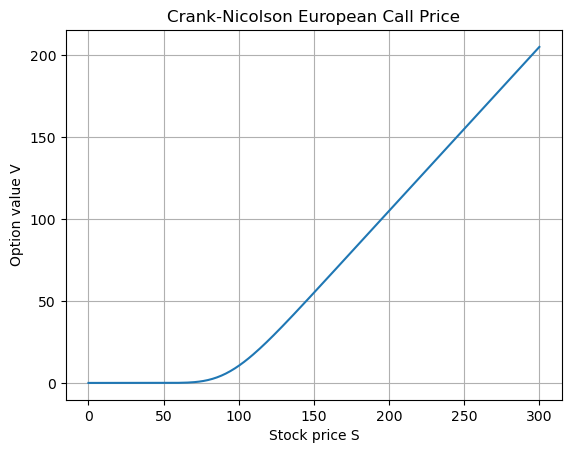

In [11]:
# Generating a plot of the option price as a function of the underlying asset price.

import matplotlib.pyplot as plt

plt.plot(S, V)
plt.xlabel("Stock price S")
plt.ylabel("Option value V")
plt.title("Crank-Nicolson European Call Price")
plt.grid()
plt.show()

In [12]:
# Comparing the result with the Black-Scholes formula for a European call option.

from src.analytical import call_price

bs_price = call_price(S0=100, K=100, T=1, r=0.05, sigma=0.2)

print(f"Analytical price:      {bs_price:.6f}")
print(f"Crank-Nicolson price:  {price:.6f}")
print(f"Absolute error:        {abs(price-bs_price):.2e}")

Analytical price:      10.450584
Crank-Nicolson price:  10.454438
Absolute error:        3.85e-03


The absolute error between my Crank-Nicolson solver and the analytical price from the solution of the Black-Scholes equation is small, indicating that it approximates the call prices well. 